In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("supply_chain_dataset1.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (91250, 15)

First 5 Rows:


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70



Column Names:
['Date', 'SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region', 'Units_Sold', 'Inventory_Level', 'Supplier_Lead_Time_Days', 'Reorder_Point', 'Order_Quantity', 'Unit_Cost', 'Unit_Price', 'Promotion_Flag', 'Stockout_Flag', 'Demand_Forecast']

Data Types:
Date                        object
SKU_ID                      object
Warehouse_ID                object
Supplier_ID                 object
Region                      object
Units_Sold                   int64
Inventory_Level              int64
Supplier_Lead_Time_Days      int64
Reorder_Point                int64
Order_Quantity               int64
Unit_Cost                  float64
Unit_Price                 float64
Promotion_Flag               int64
Stockout_Flag                int64
Demand_Forecast            float64
dtype: object

Missing Values:
Date                       0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Region                     0
Units_Sold                 0
Invent

In [3]:

# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check data types and missing values
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())


Dataset shape: (91250, 15)

Missing values:
Date                       0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Region                     0
Units_Sold                 0
Inventory_Level            0
Supplier_Lead_Time_Days    0
Reorder_Point              0
Order_Quantity             0
Unit_Cost                  0
Unit_Price                 0
Promotion_Flag             0
Stockout_Flag              0
Demand_Forecast            0
dtype: int64

Duplicate rows: 0

Date range:
2024-01-01 00:00:00 to 2024-12-30 00:00:00


In [4]:

# Inventory value
df["Inventory_Value"] = (
    df["Inventory_Level"] * df["Unit_Cost"]
)

# Difference between inventory and reorder point
df["Reorder_Gap"] = (
    df["Inventory_Level"] - df["Reorder_Point"]
)

# Actual sales minus demand forecast
df["Forecast_Error"] = (
    df["Units_Sold"] - df["Demand_Forecast"]
)

# Absolute forecast error
df["Absolute_Forecast_Error"] = (
    df["Forecast_Error"].abs()
)

# Inventory relative to reorder point
df["Inventory_to_Reorder_Ratio"] = np.where(
    df["Reorder_Point"] != 0,
    df["Inventory_Level"] / df["Reorder_Point"],
    np.nan
)

# Replenishment risk classification
df["Replenishment_Risk"] = np.select(
    [
        df["Inventory_Level"] < df["Reorder_Point"],
        df["Inventory_Level"] == df["Reorder_Point"]
    ],
    [
        "Below Reorder Point",
        "At Reorder Point"
    ],
    default="Above Reorder Point"
)

# Extract date information
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()

print("Feature engineering completed!")
display(df.head())


Feature engineering completed!


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,...,Demand_Forecast,Inventory_Value,Reorder_Gap,Forecast_Error,Absolute_Forecast_Error,Inventory_to_Reorder_Ratio,Replenishment_Risk,Year,Month,Month_Name
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,...,8.52,8258.40,213,1.48,1.48,1.562005,Above Reorder Point,2024,1,January
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,...,18.63,8021.25,196,-1.63,1.63,1.517150,Above Reorder Point,2024,1,January
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,...,39.62,7533.00,161,-4.62,4.62,1.424802,Above Reorder Point,2024,1,January
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,...,19.43,7198.20,137,4.57,4.57,1.361478,Above Reorder Point,2024,1,January
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,...,18.70,6905.25,116,2.30,2.30,1.306069,Above Reorder Point,2024,1,January


In [5]:

print("Updated dataset shape:", df.shape)

print("\nReplenishment risk counts:")
print(df["Replenishment_Risk"].value_counts())

print("\nInventory value summary:")
print(df["Inventory_Value"].describe())

print("\nForecast error summary:")
print(df["Forecast_Error"].describe())

print("\nMissing dates:", df["Date"].isna().sum())


Updated dataset shape: (91250, 24)

Replenishment risk counts:
Replenishment_Risk
Above Reorder Point    86209
Below Reorder Point     4787
At Reorder Point         254
Name: count, dtype: int64

Inventory value summary:
count    91250.000000
mean      5756.098533
std       2788.542737
min       1094.160000
25%       3521.070000
50%       5247.550000
75%       7526.787500
max      19186.960000
Name: Inventory_Value, dtype: float64

Forecast error summary:
count    91250.000000
mean        -0.027469
std          2.987263
min        -14.080000
25%         -2.030000
50%         -0.010000
75%          1.990000
max         13.000000
Name: Forecast_Error, dtype: float64

Missing dates: 0


In [6]:

# Summary statistics for important columns
display(
    df[[
        "Inventory_Level",
        "Units_Sold",
        "Demand_Forecast",
        "Reorder_Point",
        "Supplier_Lead_Time_Days",
        "Inventory_Value"
    ]].describe().round(2)
)


,Inventory_Level,Units_Sold,Demand_Forecast,Reorder_Point,Supplier_Lead_Time_Days,Inventory_Value
count,91250.00,91250.00,91250.00,91250.00,91250.00,91250.00
mean,471.52,20.05,20.08,300.07,7.98,5756.10
std,133.49,9.07,9.50,54.88,3.91,2788.54
min,168.00,0.00,0.00,201.00,2.00,1094.16
25%,370.00,13.00,12.95,252.00,4.00,3521.07
50%,461.00,20.00,19.95,300.00,8.00,5247.55
75%,564.00,27.00,26.93,346.00,11.00,7526.79
max,990.00,59.00,61.42,398.00,14.00,19186.96


In [7]:

below_reorder = df[
    df["Inventory_Level"] < df["Reorder_Point"]
]

print("Records below reorder point:", len(below_reorder))

print("\nRecords by warehouse:")
display(
    below_reorder.groupby("Warehouse_ID")
    .size()
    .reset_index(name="Below_Reorder_Records")
    .sort_values("Below_Reorder_Records", ascending=False)
)


Records below reorder point: 4787

Records by warehouse:


,Warehouse_ID,Below_Reorder_Records
4,WH_5,967
2,WH_3,964
0,WH_1,956
1,WH_2,954
3,WH_4,946


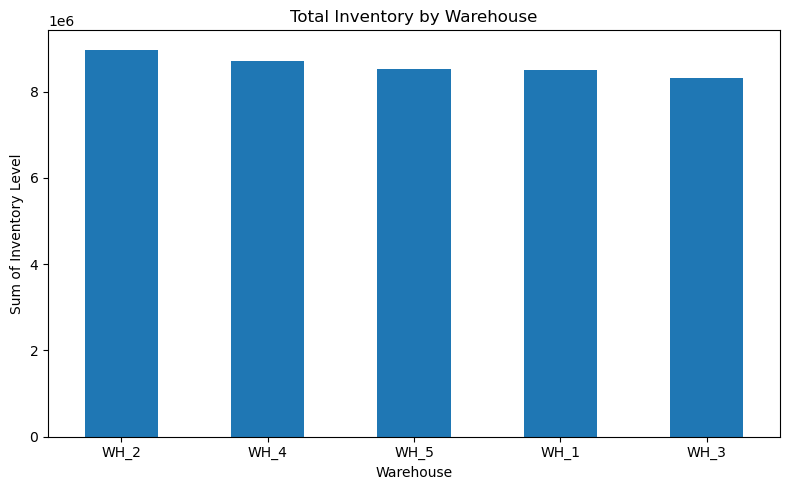

In [8]:

inventory_by_warehouse = (
    df.groupby("Warehouse_ID")["Inventory_Level"]
    .sum()
    .sort_values(ascending=False)
)

inventory_by_warehouse.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Inventory by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Sum of Inventory Level")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


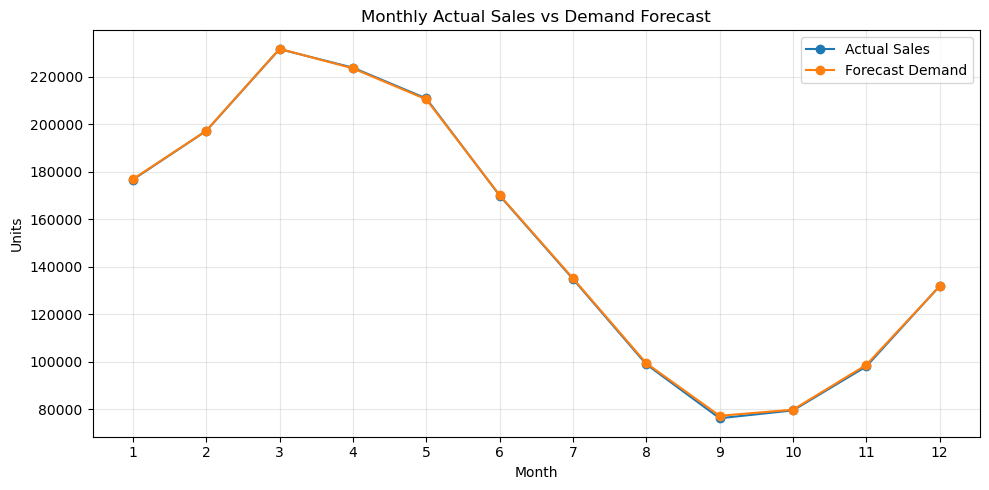

,Month,Actual_Sales,Forecast_Demand
0,1,176681,176872.59
1,2,197188,197242.80
2,3,231596,231729.13
3,4,223793,223497.82
4,5,210841,210478.01
5,6,170013,170186.13
6,7,134915,135171.72
7,8,99019,99458.29
8,9,76304,77340.05
9,10,79599,79898.56


In [9]:

demand_comparison = df.groupby("Month").agg(
    Actual_Sales=("Units_Sold", "sum"),
    Forecast_Demand=("Demand_Forecast", "sum")
).reset_index()

plt.figure(figsize=(10, 5))

plt.plot(
    demand_comparison["Month"],
    demand_comparison["Actual_Sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    demand_comparison["Month"],
    demand_comparison["Forecast_Demand"],
    marker="o",
    label="Forecast Demand"
)

plt.title("Monthly Actual Sales vs Demand Forecast")
plt.xlabel("Month")
plt.ylabel("Units")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(demand_comparison.round(2))


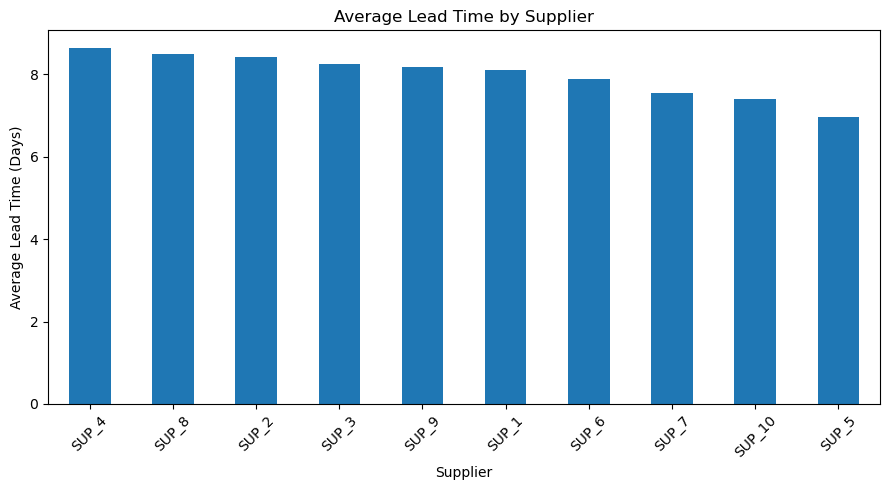

Supplier_ID
SUP_4     8.64
SUP_8     8.50
SUP_2     8.42
SUP_3     8.26
SUP_9     8.19
SUP_1     8.11
SUP_6     7.90
SUP_7     7.56
SUP_10    7.41
SUP_5     6.96
Name: Supplier_Lead_Time_Days, dtype: float64

In [10]:

supplier_lead_time = (
    df.groupby("Supplier_ID")["Supplier_Lead_Time_Days"]
    .mean()
    .sort_values(ascending=False)
)

supplier_lead_time.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Lead Time by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(supplier_lead_time.round(2))


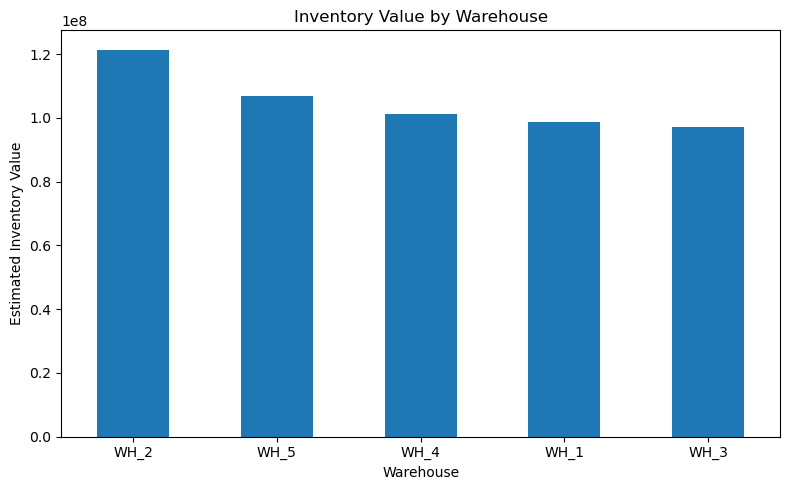

,Warehouse_ID,Inventory_Value
0,WH_2,1.213989e+08
1,WH_5,1.069279e+08
2,WH_4,1.011034e+08
3,WH_1,9.866216e+07
4,WH_3,9.715166e+07


In [11]:

inventory_value_by_warehouse = (
    df.groupby("Warehouse_ID")["Inventory_Value"]
    .sum()
    .sort_values(ascending=False)
)

inventory_value_by_warehouse.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Inventory Value by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Estimated Inventory Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    inventory_value_by_warehouse
    .reset_index()
    .round(2)
)


,Promotion_Flag,Total_Units_Sold,Average_Units_Sold,Record_Count,Promotion_Type
0,0,1599018,19.50,81980,No Promotion
1,1,230961,24.91,9270,Promotion


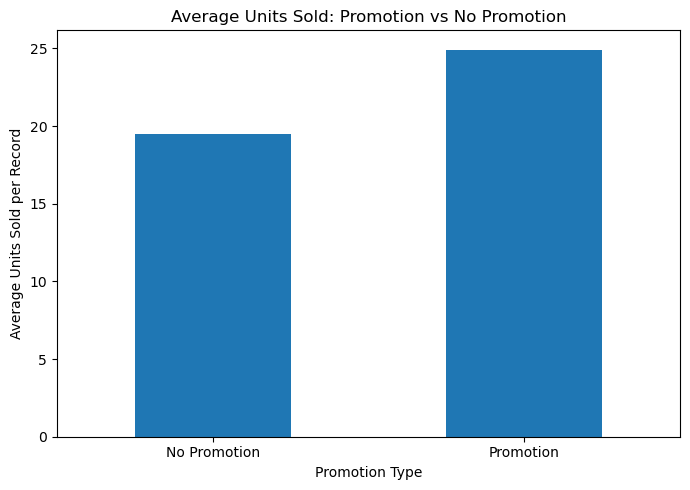

In [12]:

promotion_analysis = df.groupby("Promotion_Flag").agg(
    Total_Units_Sold=("Units_Sold", "sum"),
    Average_Units_Sold=("Units_Sold", "mean"),
    Record_Count=("Units_Sold", "size")
).reset_index()

promotion_analysis["Promotion_Type"] = (
    promotion_analysis["Promotion_Flag"]
    .map({0: "No Promotion", 1: "Promotion"})
)

display(promotion_analysis.round(2))

promotion_analysis.plot(
    x="Promotion_Type",
    y="Average_Units_Sold",
    kind="bar",
    legend=False,
    figsize=(7, 5)
)

plt.title("Average Units Sold: Promotion vs No Promotion")
plt.xlabel("Promotion Type")
plt.ylabel("Average Units Sold per Record")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,SKU_ID,Total_Actual_Sales,Total_Forecast,Mean_Absolute_Error,Forecast_Difference
15,SKU_23,36698,36717.30,2.45,-19.30
38,SKU_44,36683,36649.41,2.45,33.59
41,SKU_47,36912,36880.77,2.44,31.23
16,SKU_24,36381,36571.72,2.44,-190.72
21,SKU_29,36737,36651.31,2.43,85.69
8,SKU_17,36449,36415.65,2.42,33.35
29,SKU_36,36594,36394.07,2.42,199.93
20,SKU_28,36481,36483.19,2.42,-2.19
14,SKU_22,36646,36769.94,2.42,-123.94
1,SKU_10,36579,36632.31,2.42,-53.31


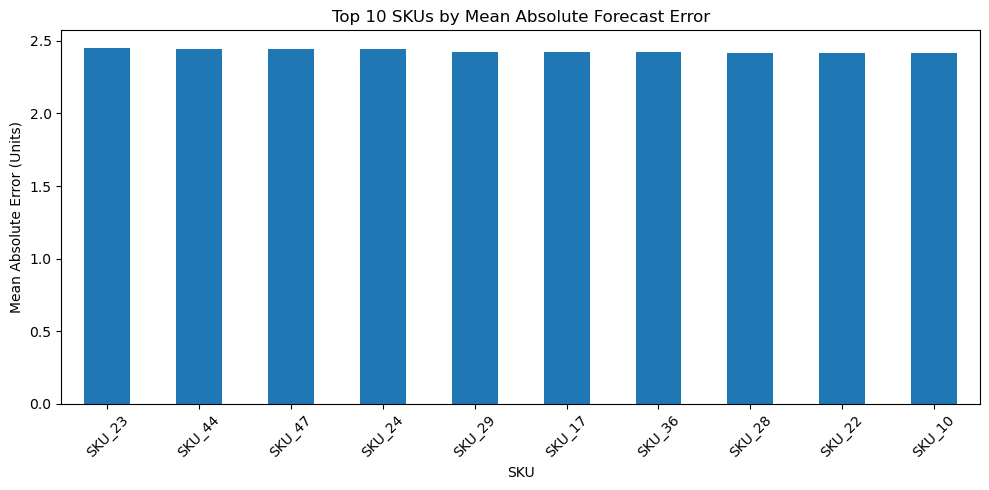

In [13]:

forecast_summary = df.groupby("SKU_ID").agg(
    Total_Actual_Sales=("Units_Sold", "sum"),
    Total_Forecast=("Demand_Forecast", "sum"),
    Mean_Absolute_Error=("Absolute_Forecast_Error", "mean")
).reset_index()

forecast_summary["Forecast_Difference"] = (
    forecast_summary["Total_Actual_Sales"]
    - forecast_summary["Total_Forecast"]
)

display(
    forecast_summary.sort_values(
        "Mean_Absolute_Error", ascending=False
    ).head(10).round(2)
)

forecast_summary.nlargest(
    10, "Mean_Absolute_Error"
).plot(
    x="SKU_ID",
    y="Mean_Absolute_Error",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top 10 SKUs by Mean Absolute Forecast Error")
plt.xlabel("SKU")
plt.ylabel("Mean Absolute Error (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Risk_Category,Record_Count,Percentage
0,Above Reorder Point,86209,94.48
1,Below Reorder Point,4787,5.25
2,At Reorder Point,254,0.28


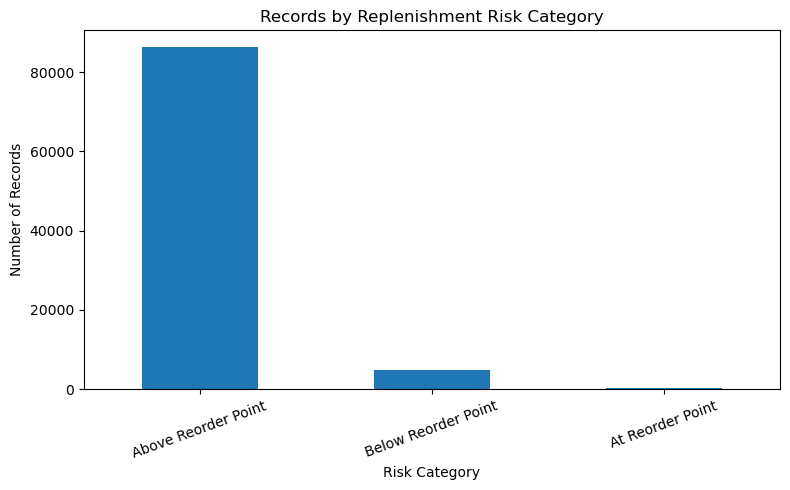

In [14]:

risk_summary = (
    df["Replenishment_Risk"]
    .value_counts()
    .reset_index()
)

risk_summary.columns = ["Risk_Category", "Record_Count"]

risk_summary["Percentage"] = (
    risk_summary["Record_Count"] / len(df) * 100
)

display(risk_summary.round(2))

risk_summary.plot(
    x="Risk_Category",
    y="Record_Count",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Records by Replenishment Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [15]:

import os

output_file = "supply_chain_cleaned.csv"

df.to_csv(output_file, index=False)

print("Processed dataset saved successfully!")
print("File location:", os.path.abspath(output_file))
print("Rows and columns:", df.shape)


Processed dataset saved successfully!
File location: C:\Users\mmk29\Downloads\DV\supply_chain_cleaned.csv
Rows and columns: (91250, 24)


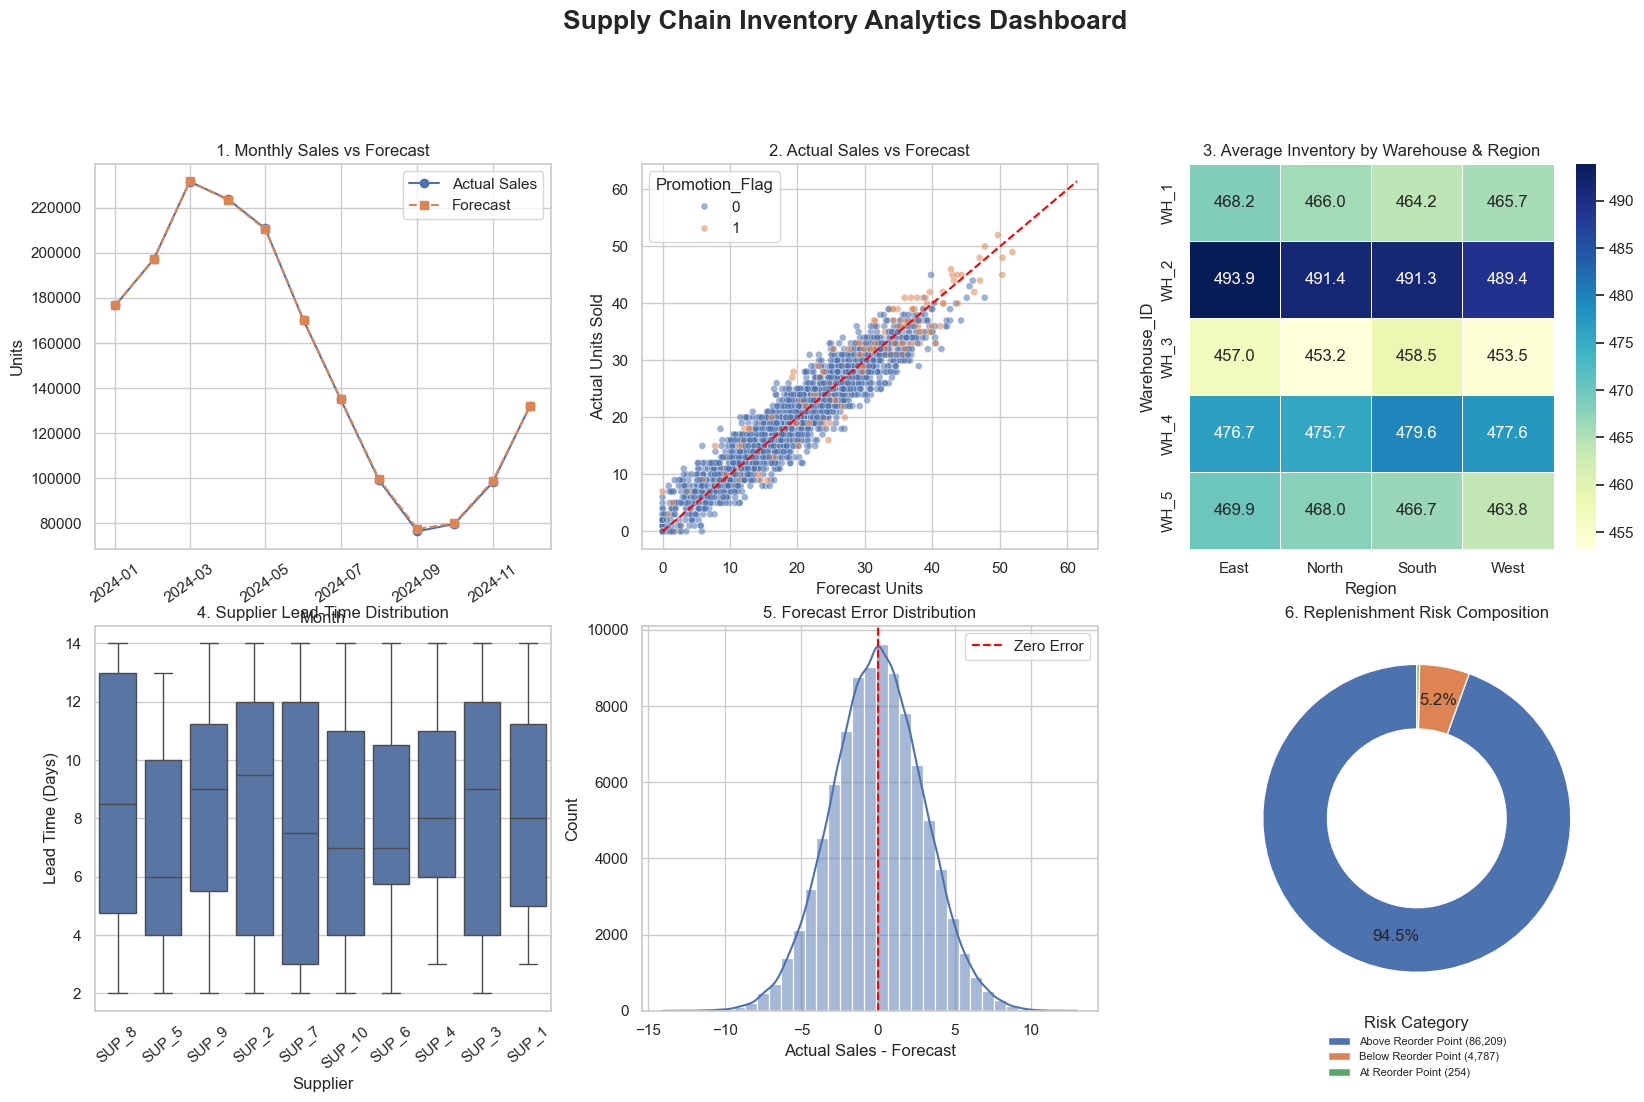

In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle(
    "Supply Chain Inventory Analytics Dashboard",
    fontsize=19, fontweight="bold", y=1.02
)

# 1. LINE CHART: Monthly actual sales vs forecast
monthly = df.groupby(
    df["Date"].dt.to_period("M")
).agg(
    Actual_Sales=("Units_Sold", "sum"),
    Forecast=("Demand_Forecast", "sum")
)

monthly.index = monthly.index.to_timestamp()

axes[0, 0].plot(
    monthly.index, monthly["Actual_Sales"],
    marker="o", label="Actual Sales"
)
axes[0, 0].plot(
    monthly.index, monthly["Forecast"],
    marker="s", linestyle="--", label="Forecast"
)
axes[0, 0].set_title("1. Monthly Sales vs Forecast")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Units")
axes[0, 0].tick_params(axis="x", rotation=35)
axes[0, 0].legend()

# 2. SCATTER PLOT: Actual sales vs forecast
sample = df.sample(
    n=min(2500, len(df)), random_state=42
)

sns.scatterplot(
    data=sample,
    x="Demand_Forecast",
    y="Units_Sold",
    hue="Promotion_Flag",
    alpha=0.55,
    s=25,
    ax=axes[0, 1]
)

limit = max(
    df["Demand_Forecast"].max(),
    df["Units_Sold"].max()
)

axes[0, 1].plot(
    [0, limit], [0, limit],
    linestyle="--", color="red",
    label="Actual = Forecast"
)
axes[0, 1].set_title("2. Actual Sales vs Forecast")
axes[0, 1].set_xlabel("Forecast Units")
axes[0, 1].set_ylabel("Actual Units Sold")

# 3. HEATMAP: Warehouse vs region
heatmap_data = df.pivot_table(
    index="Warehouse_ID",
    columns="Region",
    values="Inventory_Level",
    aggfunc="mean"
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0, 2]
)

axes[0, 2].set_title("3. Average Inventory by Warehouse & Region")

# 4. BOX PLOT: Supplier lead time
sns.boxplot(
    data=df,
    x="Supplier_ID",
    y="Supplier_Lead_Time_Days",
    ax=axes[1, 0]
)

axes[1, 0].set_title("4. Supplier Lead-Time Distribution")
axes[1, 0].set_xlabel("Supplier")
axes[1, 0].set_ylabel("Lead Time (Days)")
axes[1, 0].tick_params(axis="x", rotation=40)

# 5. HISTOGRAM: Forecast error
sns.histplot(
    data=df,
    x="Forecast_Error",
    bins=35,
    kde=True,
    ax=axes[1, 1]
)

axes[1, 1].axvline(
    0, color="red", linestyle="--",
    label="Zero Error"
)
axes[1, 1].set_title("5. Forecast Error Distribution")
axes[1, 1].set_xlabel("Actual Sales - Forecast")
axes[1, 1].legend()


# 6. DONUT CHART: Replenishment Risk
risk_counts = df["Replenishment_Risk"].value_counts()

wedges, texts, autotexts = axes[1, 2].pie(
    risk_counts.values,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.42,
        "edgecolor": "white"
    }
)

axes[1, 2].legend(
    wedges,
    [
        f"{label} ({count:,})"
        for label, count in risk_counts.items()
    ],
    title="Risk Category",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.20),
    fontsize=8,
    frameon=False
)

axes[1, 2].set_title("6. Replenishment Risk Composition")
axes[1, 2].set_aspect("equal")



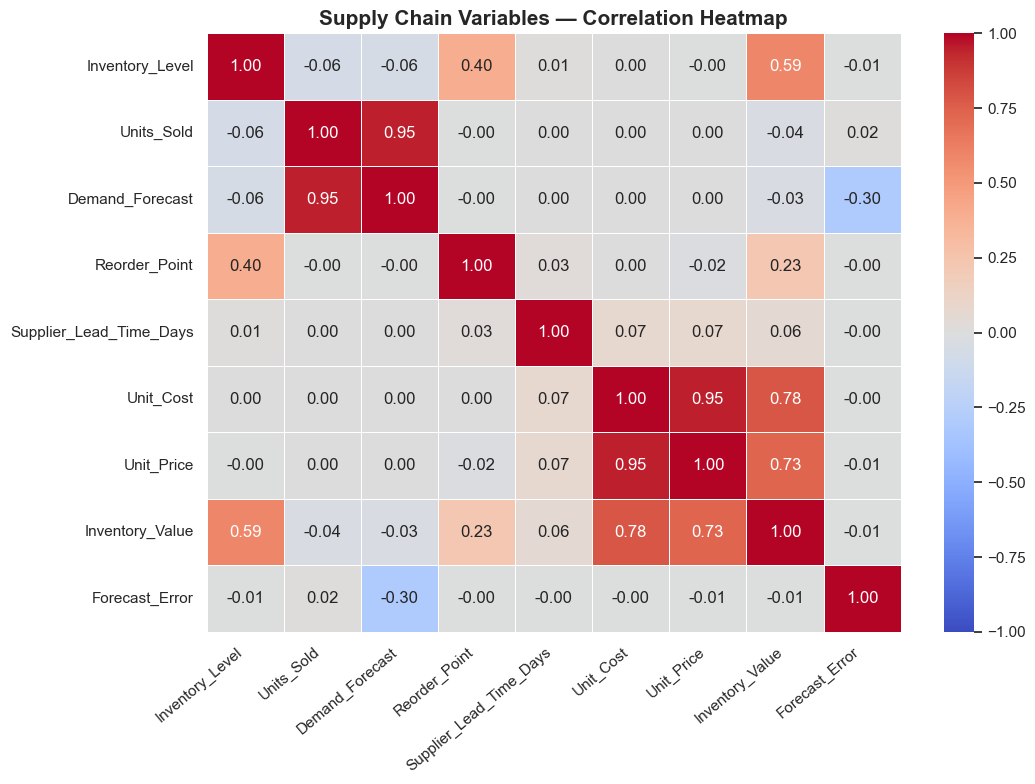

In [17]:

numeric_columns = [
    "Inventory_Level",
    "Units_Sold",
    "Demand_Forecast",
    "Reorder_Point",
    "Supplier_Lead_Time_Days",
    "Unit_Cost",
    "Unit_Price",
    "Inventory_Value",
    "Forecast_Error"
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Supply Chain Variables — Correlation Heatmap",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:

%pip install squarify


Note: you may need to restart the kernel to use updated packages.


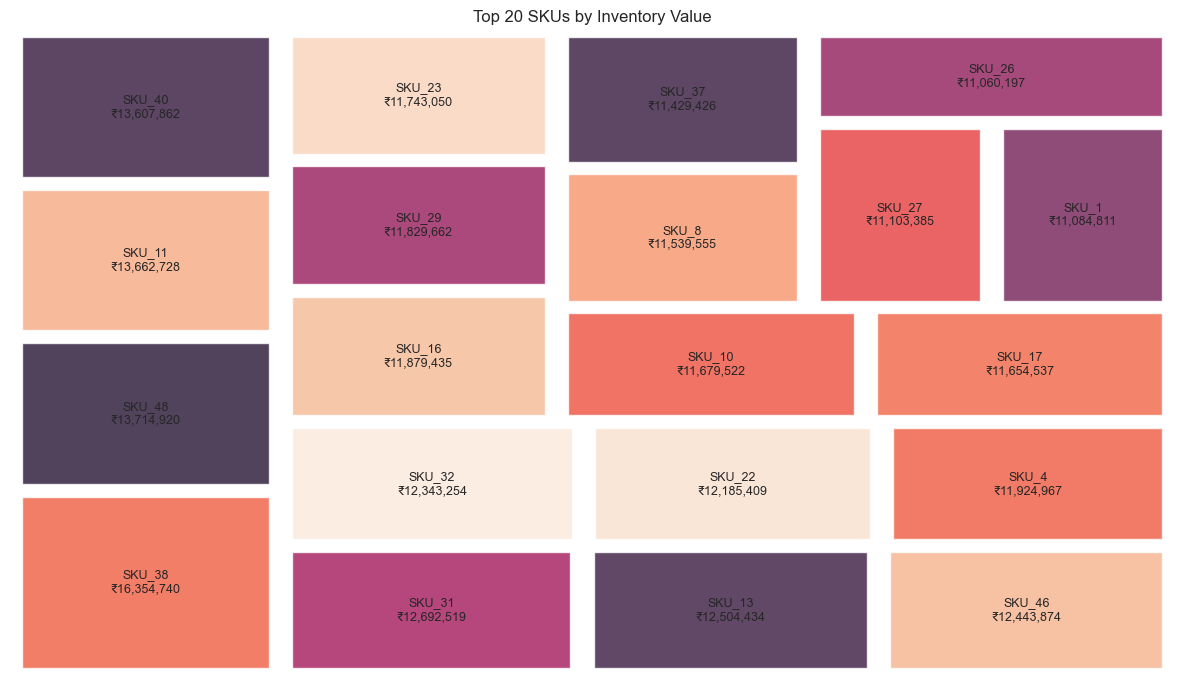

In [19]:

import squarify
import matplotlib.pyplot as plt

sku_value = (
    df.groupby("SKU_ID")["Inventory_Value"]
    .sum()
    .sort_values(ascending=False)
)

sku_value = sku_value[sku_value > 0].head(20)

plt.figure(figsize=(12, 7))

squarify.plot(
    sizes=sku_value.values,
    label=[
        f"{sku}\n₹{value:,.0f}"
        for sku, value in sku_value.items()
    ],
    alpha=0.8,
    pad=True,
    text_kwargs={"fontsize": 9}
)

plt.title("Top 20 SKUs by Inventory Value")
plt.axis("off")
plt.tight_layout()
plt.show()


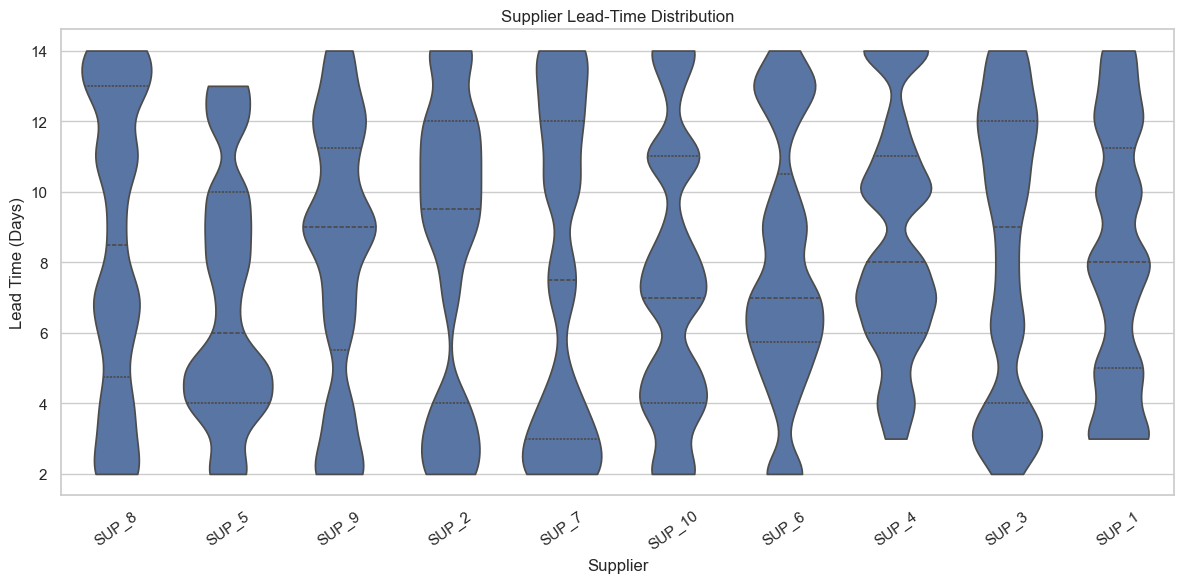

In [20]:

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x="Supplier_ID",
    y="Supplier_Lead_Time_Days",
    inner="quartile",
    cut=0
)

plt.title("Supplier Lead-Time Distribution")
plt.xlabel("Supplier")
plt.ylabel("Lead Time (Days)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


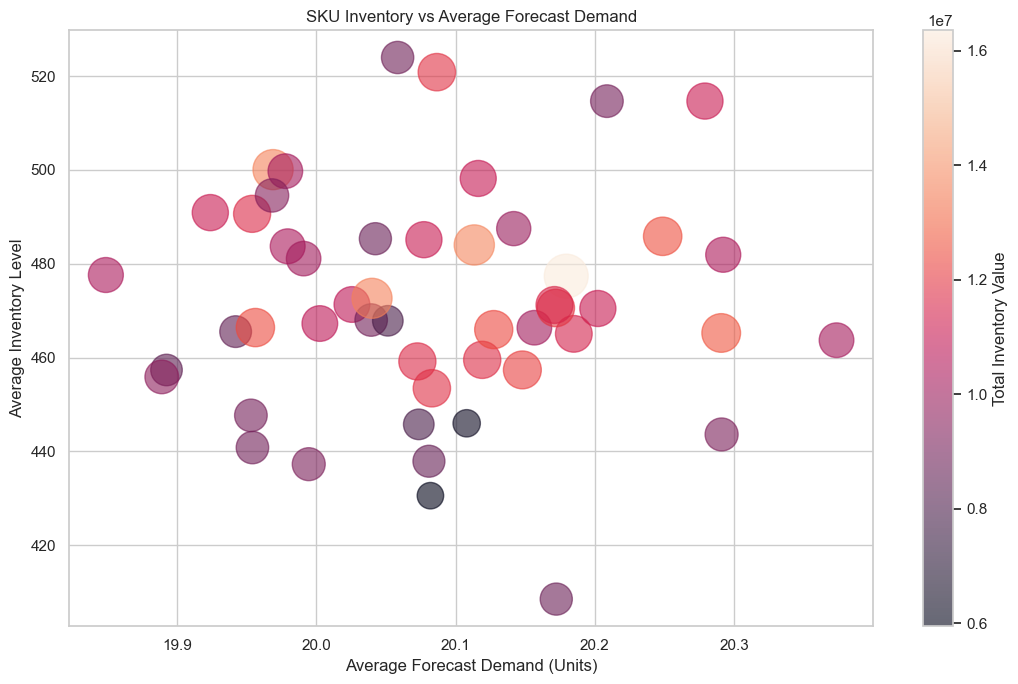

In [21]:

bubble_data = (
    df.groupby("SKU_ID")
    .agg(
        Average_Inventory=("Inventory_Level", "mean"),
        Average_Demand=("Demand_Forecast", "mean"),
        Total_Inventory_Value=("Inventory_Value", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    bubble_data["Average_Demand"],
    bubble_data["Average_Inventory"],
    s=(
        bubble_data["Total_Inventory_Value"]
        / bubble_data["Total_Inventory_Value"].max()
        * 1000
    ),
    c=bubble_data["Total_Inventory_Value"],
    alpha=0.6
)

plt.colorbar(scatter, label="Total Inventory Value")
plt.title("SKU Inventory vs Average Forecast Demand")
plt.xlabel("Average Forecast Demand (Units)")
plt.ylabel("Average Inventory Level")
plt.tight_layout()
plt.show()


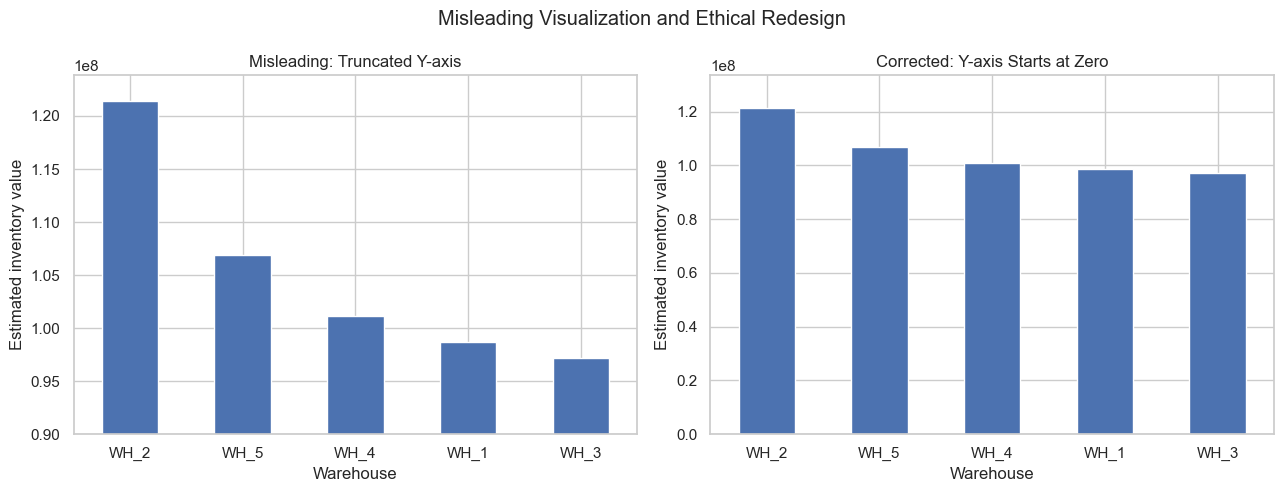

The truncated axis exaggerates differences; the zero-baseline chart is the ethical comparison.


In [22]:
import matplotlib.pyplot as plt

warehouse_value = df.groupby("Warehouse_ID")["Inventory_Value"].sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
warehouse_value.plot(kind="bar", ax=axes[0])
axes[0].set_ylim(90_000_000, warehouse_value.max() * 1.02)
axes[0].set_title("Misleading: Truncated Y-axis")
axes[0].set_xlabel("Warehouse")
axes[0].set_ylabel("Estimated inventory value")
axes[0].tick_params(axis="x", rotation=0)
warehouse_value.plot(kind="bar", ax=axes[1])
axes[1].set_ylim(0, warehouse_value.max() * 1.10)
axes[1].set_title("Corrected: Y-axis Starts at Zero")
axes[1].set_xlabel("Warehouse")
axes[1].set_ylabel("Estimated inventory value")
axes[1].tick_params(axis="x", rotation=0)
fig.suptitle("Misleading Visualization and Ethical Redesign")
plt.tight_layout()
plt.show()
print("The truncated axis exaggerates differences; the zero-baseline chart is the ethical comparison.")
